In [1]:
import os
import sys
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from collections import defaultdict

In [2]:
sys.path.append(os.path.abspath('..'))
from src.student_mental_health import config, preprocessing, evaluation, training

In [3]:
config.print_title('make a copy of the raw dataset')
df_clean = config.load_raw().copy()
display(df_clean.head())

make a copy of the raw dataset


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [4]:
config.print_title('Fixing Inconsistent Values Between Screen Time and Social Media Hours')

df_clean = preprocessing.clean_data(df_clean)

print('Done')

Fixing Inconsistent Values Between Screen Time and Social Media Hours
Done


In [5]:
config.print_title('Split Dataset into Training and Testing Sets')

X_train, X_test, y_train, y_test = preprocessing.split_data(df_clean)

print(f'X_train shape : {X_train.shape}')
print(f'y_train shape : {y_train.shape}')
print(f'X_test shape  : {X_test.shape}')
print(f'y_test shape  : {y_test.shape}')

Split Dataset into Training and Testing Sets
X_train shape : (1600, 15)
y_train shape : (1600,)
X_test shape  : (400, 15)
y_test shape  : (400,)


In [6]:
config.print_title('Get numerical columns in X_train that contain outliers')
num_cols = config.get_columns(X_train, 'number')

x = preprocessing.check_outliers(X_train, num_cols)

columns_containing_outliers = [k for k, v in x.items() if len(v) != 0 ]
columns_containing_outliers



Get numerical columns in X_train that contain outliers


['Age',
 'Sleep_Hours',
 'Study_Hours_Per_Week',
 'GPA',
 'Social_Media_Hours',
 'Screen_Time_Hours',
 'Attendance_Rate']

In [7]:
config.print_title('Handling Outliers Using IQR (Capping)')

X_train, X_test = preprocessing.cap_outliers(X_train, 
                                             X_test, 
                                             columns_containing_outliers )

print('Done')

Handling Outliers Using IQR (Capping)
Done


In [8]:
# Keep the target column alongside the features for storage
train_df = X_train.copy()
train_df[config.TARGET_COLUMN] = y_train

test_df = X_test.copy()
test_df[config.TARGET_COLUMN] = y_test

# Save processed datasets
config.PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True )

train_df.to_csv( config.PROCESSED_DATA_DIR / 'train.csv', index=False )

test_df.to_csv( config.PROCESSED_DATA_DIR / 'test.csv', index=False )


In [9]:
config.print_title('validate data distribution across y_train and y_test')

print('Training distribution:')
display(y_train.value_counts(normalize=True).mul(100).round(2))

print('Testing distribution:')
display(y_test.value_counts(normalize=True).mul(100).round(2))

validate data distribution across y_train and y_test
Training distribution:


Mental_Health_Risk
High      34.0
Medium    33.0
Low       33.0
Name: proportion, dtype: float64

Testing distribution:


Mental_Health_Risk
High      34.0
Medium    33.0
Low       33.0
Name: proportion, dtype: float64

In [12]:
config.print_title('Identify Numerical and Categorical Features')

numerical_features = config.get_columns(X_train, 'number')


categorical_features = config.get_columns(X_train, 'object')


print('Numerical Features:')
print(numerical_features)
print("=" * 50)
print('Categorical Features:')
print(categorical_features)

Identify Numerical and Categorical Features
Numerical Features:
['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']
Categorical Features:
['Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History']


In [13]:
config.print_title('Build Preprocessing Pipelines')

preprocessor = training.build_preprocessor(X_train)

display(preprocessor)

Build Preprocessing Pipelines


ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Age', 'Year_of_Study', 'Sleep_Hours',
                                  'Study_Hours_Per_Week', 'GPA',
                                  'Social_Media_Hours', 'Screen_Time_Hours',
                                  'Financial_Stress', 'Family_Support',
                                  'Attendance_Rate']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Gender', 'Physical_Activity',
                                  'Part_Time_Job', 'Diet_Quality',
                                  'Previous_Mental_Health_History'])])

# **Model training and evaluation**

In [14]:
models = training.get_models()
print(models.keys())

dict_keys(['Logistic Regression', 'Random Forest', 'SVM'])


In [15]:
config.print_title('Create Model Pipelines Dynamically')

model_pipelines = training.build_model_pipelines(preprocessor, models )

print(f'Dictionary keys: {list(model_pipelines.keys())}')

Create Model Pipelines Dynamically
Dictionary keys: ['Logistic Regression', 'Random Forest', 'SVM']


In [16]:
config.print_title('Training Classification Models')

model_pipelines = training.train_models(model_pipelines, X_train, y_train )

Training Classification Models
Training Logistic Regression
Training Logistic Regression: Done
Training Random Forest


Training Random Forest: Done
Training SVM
Training SVM: Done
All models training: Done


In [17]:
config.print_title('Generate Predictions')

predictions = defaultdict()

for name, pipeline in model_pipelines.items():

    y_pred = pipeline.predict(X_test)

    predictions[name] = y_pred

    print(f'{name}: predictions added to prediction dictionary')

Generate Predictions
Logistic Regression: predictions added to prediction dictionary
Random Forest: predictions added to prediction dictionary
SVM: predictions added to prediction dictionary


In [18]:
config.print_title('Evaluate Model Performance')

evaluation_results = defaultdict(dict)

for name, y_pred in predictions.items():

    evaluation_results[name] = evaluation.metrics(y_test, y_pred)

    print(f'{name}: Evaluation Done')

Evaluate Model Performance
Logistic Regression: Evaluation Done
Random Forest: Evaluation Done
SVM: Evaluation Done


In [19]:
config.print_title('Generate Classification Reports')

for name, y_pred in predictions.items():
    
    print(f'\n{name}')
    print('=' * 60)

    print(classification_report(y_test, y_pred, zero_division=0))

Generate Classification Reports

Logistic Regression
              precision    recall  f1-score   support

        High       0.81      0.82      0.82       136
         Low       0.81      0.81      0.81       132
      Medium       0.63      0.62      0.63       132

    accuracy                           0.75       400
   macro avg       0.75      0.75      0.75       400
weighted avg       0.75      0.75      0.75       400


Random Forest
              precision    recall  f1-score   support

        High       0.72      0.75      0.74       136
         Low       0.79      0.80      0.79       132
      Medium       0.56      0.54      0.55       132

    accuracy                           0.69       400
   macro avg       0.69      0.69      0.69       400
weighted avg       0.69      0.69      0.69       400


SVM
              precision    recall  f1-score   support

        High       0.79      0.80      0.80       136
         Low       0.77      0.80      0.78       132
  

In [20]:
config.print_title('Compare Model Performance')

evaluation_df = pd.DataFrame(evaluation_results).T

display(evaluation_df.round(4))

Compare Model Performance


,Accuracy,Precision,Recall,F1-Score
Logistic Regression,0.7525,0.7516,0.7525,0.7520
Random Forest,0.6950,0.6924,0.6950,0.6935
SVM,0.7200,0.7171,0.7200,0.7184


Generate Confusion Matrices


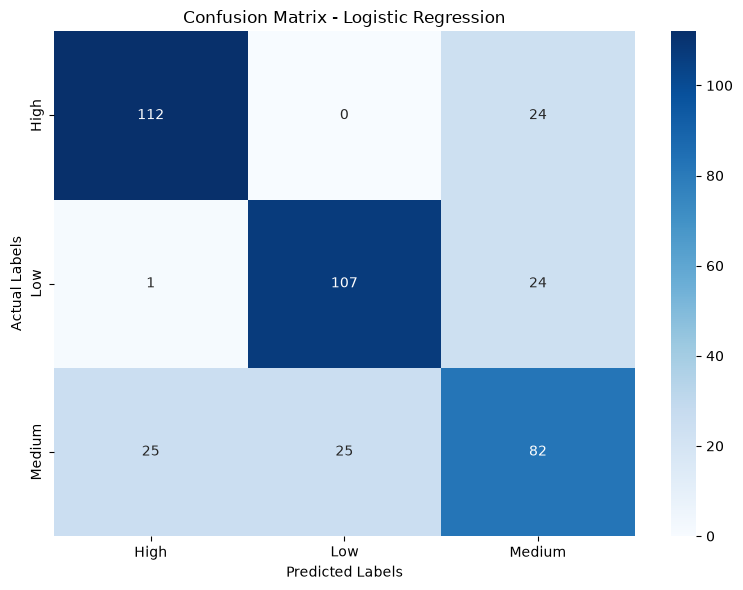

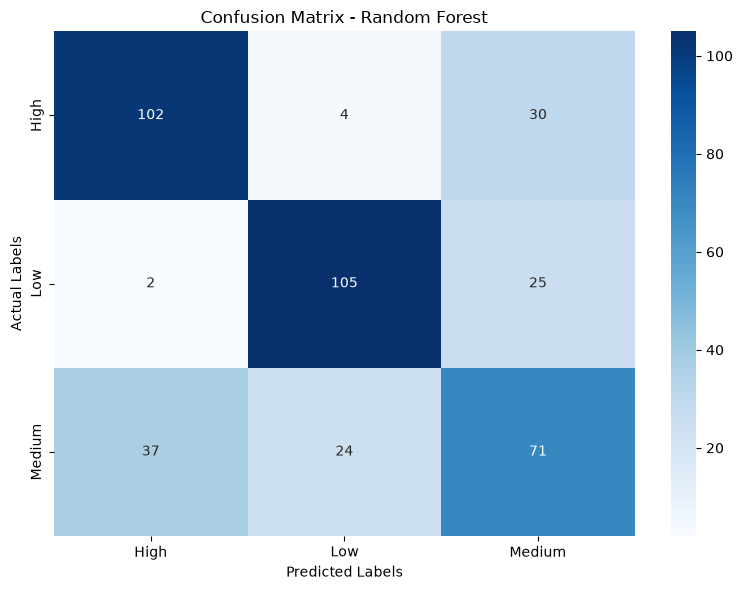

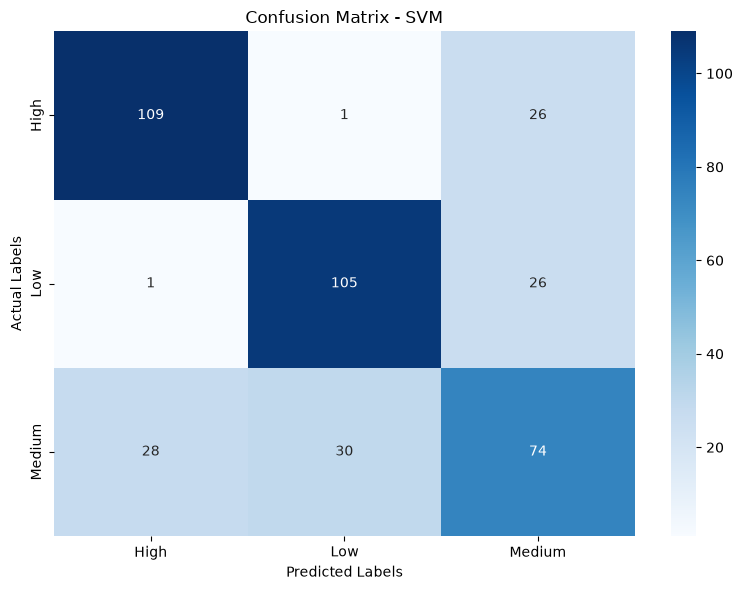

In [21]:
config.print_title('Generate Confusion Matrices')

for name, y_pred in predictions.items():

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(8, 6))

    sns.heatmap(cm,
                annot=True,
                fmt='d',
                cmap='Blues',
                xticklabels=model_pipelines[name].classes_,
                yticklabels=model_pipelines[name].classes_ )

    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted Labels')
    plt.ylabel('Actual Labels')
    plt.tight_layout()
    plt.show()

In [22]:
config.print_title('Calculate ROC-AUC Scores')

roc_auc_results = defaultdict()

for name, pipeline in model_pipelines.items():

    y_proba = pipeline.predict_proba(X_test)

    classes = pipeline.classes_

    roc_auc = roc_auc_score(y_test, y_proba, multi_class='ovr', average='weighted', labels=classes )

    roc_auc_results[name] = roc_auc

    print(f'{name}: ROC-AUC = {roc_auc:.4f}')


Calculate ROC-AUC Scores
Logistic Regression: ROC-AUC = 0.9146
Random Forest: ROC-AUC = 0.8533
SVM: ROC-AUC = 0.8872


In [23]:
config.print_title('Optimize Selected Models Using GridSearchCV')

selected_models = ['Logistic Regression', 'SVM']

grid_searches, best_estimators = training.optimize_models(model_pipelines, X_train, y_train, selected_models )

print(grid_searches['Logistic Regression'].best_score_)
print(grid_searches['SVM'].best_score_)

Optimize Selected Models Using GridSearchCV

Optimizing Logistic Regression
Fitting 5 folds for each of 10 candidates, totalling 50 fits



Logistic Regression fine-tuning completed
Best parameters: {'classifier__C': 10, 'classifier__class_weight': 'balanced', 'classifier__penalty': 'l2', 'classifier__solver': 'lbfgs'}
Best CV F1-score: 0.7539

Optimizing SVM
Fitting 5 folds for each of 24 candidates, totalling 120 fits

SVM fine-tuning completed
Best parameters: {'classifier__C': 0.1, 'classifier__class_weight': None, 'classifier__kernel': 'linear'}
Best CV F1-score: 0.7475

All fine-tuning completed
0.7539388339768693
0.7474719090769641


In [24]:
print(grid_searches['Logistic Regression'].best_score_)
print(grid_searches['SVM'].best_score_)


0.7539388339768693
0.7474719090769641


In [25]:
config.print_title('Final Model Performance Comparison')

evaluation_df['ROC-AUC'] = pd.Series(roc_auc_results)

display(evaluation_df.round(4))

Final Model Performance Comparison


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.7525,0.7516,0.7525,0.7520,0.9146
Random Forest,0.6950,0.6924,0.6950,0.6935,0.8533
SVM,0.7200,0.7171,0.7200,0.7184,0.8872


In [26]:
config.print_title('Evaluate Optimized Models on Test Set')

optimized_predictions = defaultdict()
optimized_results = defaultdict(dict)
optimized_roc_auc = defaultdict()

for name, pipeline in best_estimators.items():

    y_pred = pipeline.predict(X_test)

    optimized_predictions[name] = y_pred

    optimized_results[name] = evaluation.metrics(y_test, y_pred)

    # Calculate ROC-AUC
    y_proba = pipeline.predict_proba(X_test)

    roc_auc = roc_auc_score(y_test, 
                            y_proba, 
                            multi_class='ovr', 
                            average='weighted', 
                            labels=pipeline.classes_ )

    optimized_roc_auc[name] = roc_auc

    print(f'{name}: Evaluation completed')
    
print('\nOptimized Models Performance:')

optimized_df = pd.DataFrame(optimized_results).T

optimized_df['ROC-AUC'] = pd.Series(optimized_roc_auc)

display(optimized_df.round(4))

Evaluate Optimized Models on Test Set
Logistic Regression: Evaluation completed
SVM: Evaluation completed

Optimized Models Performance:


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.7550,0.7546,0.7550,0.7548,0.9146
SVM,0.7525,0.7534,0.7525,0.7529,0.9106


In [27]:
config.print_title('Save Final Model Pipeline')

final_model_name = 'Logistic Regression'

final_model = best_estimators[final_model_name]

model_path = training.save_model(final_model, final_model_name)

Save Final Model Pipeline
Model saved: /home/h3/Desktop/brief/student_mental_health/models/logistic_regression.joblib
